# Membrane Swelling during Operation

This notebook investigates the amount of membrane swelling during operation

TODO: 
- [x] find method to quantify membrane swelling, ideas: ~~strike if not useful~~
    - [x] skeletonize CL and get distance as proxy for membrane thickness

In [5]:
# paths
import os
import socket
host = socket.gethostname()
if host == 'mpc2959.psi.ch':
    gitpath = '/mpc/homes/fische_r/lib/co2ely-tomcat'
    toppath = '/mpc/homes/fische_r/NAS/DASCOELY'
    toppathSSD = '/mnt/SSD/fische_r/COELY'
    temppath = '/mnt/SSD/fische_r/tmp/joblib_tmp'
    
path_01_4D = os.path.join(toppathSSD, '01_rotated_3p1D') #h5 with rotated data
path_02_4D = os.path.join(toppathSSD, '02_registered_3p1D') #h5 with registered data

image_output = os.path.join(toppath, 'plots')
if not os.path.exists(image_output):
    os.mkdir(image_output)
image_output = os.path.join(toppath, 'plots', '04_membrane_swelling')
if not os.path.exists(image_output):
    os.mkdir(image_output)
    
    
# modules
import xarray as xr
# import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import cm
import matplotlib.colors as mcolors
from mpl_toolkits.axes_grid1 import make_axes_locatable
# from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar
# import matplotlib.font_manager as fm
# fontprops = fm.FontProperties(size=14)

import skimage
import numpy as np
from joblib import Parallel, delayed
import cupy as cp
import cucim



In [6]:
import warnings


## Test skeletonize

In [7]:
CLth = 15500

In [8]:
sample = '7x'

In [9]:
file = '01_'+sample+'_rotated_3p1D.nc'
imagepath = os.path.join(path_01_4D, file)
data = xr.open_dataset(imagepath)
images = [im for im in data.keys() if im[3:7] == 'imag']
images.sort()

In [10]:
test = data[images[10]].data

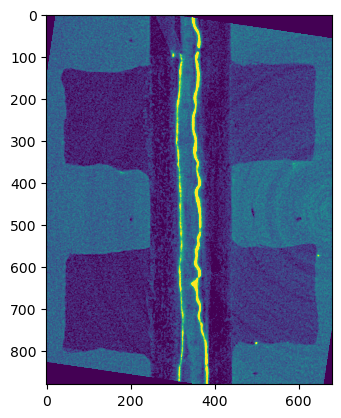

In [11]:
plt.imshow(test[:,:,200], vmin=11000, vmax = 17000)

In [12]:
# data.close()

In [13]:
def skeletonize_2D(im):
    im_skel = np.zeros(im.shape, dtype=bool)
    results = Parallel(n_jobs=16, temp_folder=temppath)(delayed(skimage.morphology.skeletonize)(im[i,:,:]) for i in range(im.shape[0]))
    for i in range(im.shape[0]):
        im_skel[i,:,:,] = results[i]
    return im_skel

In [14]:
def find_CL_2D(im2D):
    pos = np.zeros((2,im2D.shape[0]))
    for i in range(im2D.shape[0]):
        search = np.argwhere(im2D[i,:])
        if len(search) == 2:
            pos[0,i] = search[0][0]
            pos[1,i] = search[1][0]
    return pos

def find_CL_3D(im):
    results = Parallel(n_jobs=32, temp_folder=temppath)(delayed(find_CL_2D)(im[:,:,i]) for i in range(im.shape[2]))
    pos = np.zeros((results[0].shape[0], results[0].shape[1], len(results)))
    for i in range(len(results)):
        pos[:,:,i] = results[i]
    return pos

def median_warn_sup(th):
    return np.nanmedian(th, axis=1)

def get_membrane_thickness(im, i, CLth=CLth):
    warnings.filterwarnings("ignore") #ignore numpy whining and spamming nan-warnings, inside function because joblib spawns workers with default settings on warnings?!
    im = im>CLth
    
    gpu_id = 1 + i%4 #use gpus 1 through 4, leaving the big A40 (0) alone
    
    with cp.cuda.Device(gpu_id):
        im = cp.array(im)
        im = cucim.skimage.morphology.binary_opening(im, footprint=cucim.skimage.morphology.ball(1.5))
        im = cp.asnumpy(im)
        mempool = cp.get_default_memory_pool()
        mempool.free_all_blocks()
        
    im = skeletonize_2D(im)
    
    pos = find_CL_3D(im)
    th = pos[1,...] - pos[0,...]
    th[th<5] = np.nan
    th[th>200] = np.nan
    median_thickness = np.nanmedian(th, axis=1)
    
    return median_thickness, pos #carry pos to see if CL buckling gives a signal

In [15]:
# n_jobs is limited by how many jobs one GPU can take into its RAM, 16 seems ok, also 32, but might hit CPU-RAM limitations

results = Parallel(n_jobs=32, temp_folder=temppath)(delayed(get_membrane_thickness)(data[image].data, i) for (image, i) in zip(images, range(len(images))))

In [20]:
time = data['t_utc'] - data['t_utc'].min()
time = time/60

In [17]:
data.close()

AttributeError: 'list' object has no attribute 'get_array'

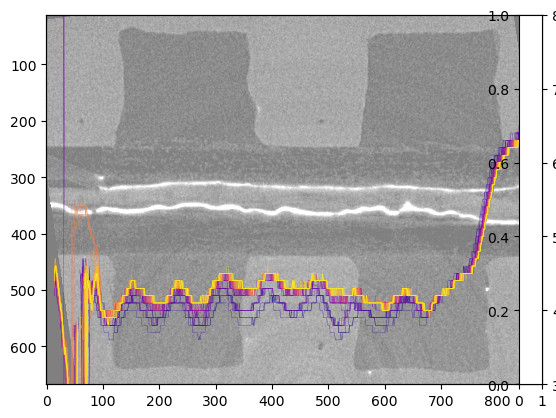

In [22]:
fig, ax = plt.subplots()

ax.imshow(test[:,:,200].T, vmin=11000, vmax = 17000, cmap = 'gray', alpha=0.5)

ax2 = ax.twinx()
normalize = mcolors.Normalize(vmin=0, vmax=time.max())
colormap = cm.plasma


for i in range(len(images)):
    im_plot = ax2.plot(results[i][0], color = colormap(normalize(time[i])), linewidth=0.2)

    
ax2.set_ylim(30,80)
divider = make_axes_locatable(ax2)
cax = divider.append_axes('right', size='5%', pad=0.05)
fig.colorbar(im_plot, cax=cax, orientation='vertical', label='time [min]')

In [23]:
im_plot